# Practical 3: Exploratory Data Analysis

**Dataset:** TeachingRatings.csv

**Aim:** Explore tenure, age and evaluation scores of instructors using tables and charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ratings = pd.read_csv("TeachingRatings.csv")
print(ratings.shape)
ratings.head()

(463, 13)


   rownames minority  age  gender  ... tenure  students  allstudents prof
0         1      yes   36  female  ...    yes        24           43    1
1         2       no   59    male  ...    yes        17           20    2
2         3       no   51    male  ...    yes        55           55    3
3         4       no   40  female  ...    yes        40           46    4
4         5       no   31  female  ...    yes        42           48    5

[5 rows x 13 columns]

In [2]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     463 non-null    int64  
 1   minority     463 non-null    str    
 2   age          463 non-null    int64  
 3   gender       463 non-null    str    
 4   credits      463 non-null    str    
 5   beauty       463 non-null    float64
 6   eval         463 non-null    float64
 7   division     463 non-null    str    
 8   native       463 non-null    str    
 9   tenure       463 non-null    str    
 10  students     463 non-null    int64  
 11  allstudents  463 non-null    int64  
 12  prof         463 non-null    int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 47.2 KB


**Result:** The dataset has 463 records and 13 columns. There are no missing values, so no cleaning is needed.

In [3]:
ratings.describe().round(3)

       rownames      age   beauty     eval  students  allstudents     prof
count   463.000  463.000  463.000  463.000   463.000      463.000  463.000
mean    232.000   48.365    0.000    3.998    36.624       55.177   45.434
std     133.801    9.803    0.789    0.555    45.018       75.073   27.509
min       1.000   29.000   -1.450    2.100     5.000        8.000    1.000
25%     116.500   42.000   -0.656    3.600    15.000       19.000   20.000
50%     232.000   48.000   -0.068    4.000    23.000       29.000   44.000
75%     347.500   57.000    0.546    4.400    40.000       60.000   70.500
max     463.000   73.000    1.970    5.000   380.000      581.000   94.000

**Result:** The average age is about 48 years and the average evaluation score is about 4.0 out of 5.

In [4]:
minority_group = ratings[ratings["minority"] == "yes"]
other_group = ratings[ratings["minority"] == "no"]
minority_tenure = round((minority_group["tenure"] == "yes").mean() * 100, 2)
other_tenure = round((other_group["tenure"] == "yes").mean() * 100, 2)
print("Minority instructors with tenure    :", minority_tenure, "%")
print("Non-minority instructors with tenure:", other_tenure, "%")
print()
print(pd.crosstab(ratings["minority"], ratings["tenure"]))
higher = "more" if minority_tenure > other_tenure else "less"

Minority instructors with tenure    : 84.38 %
Non-minority instructors with tenure: 76.94 %

tenure    no  yes
minority         
no        92  307
yes       10   54


**Result:** 84.38% of minority instructors have tenure, compared with 76.94% of non-minority instructors. Tenure status differs slightly by minority status, with minority instructors more often tenured in this data. The table alone does not prove that minority status is the cause.

In [5]:
age_summary = ratings.groupby("tenure")["age"].agg(["mean", "std"]).round(2)
age_summary

         mean    std
tenure              
no      50.19   6.95
yes     47.85  10.42

In [6]:
tenured_mean = age_summary.loc["yes", "mean"]
tenured_std = age_summary.loc["yes", "std"]
untenured_mean = age_summary.loc["no", "mean"]
untenured_std = age_summary.loc["no", "std"]
print(tenured_mean, tenured_std, untenured_mean, untenured_std)

47.85 10.42 50.19 6.95


**Result:** Tenured instructors have a mean age of 47.85 years with standard deviation 10.42. Untenured instructors have a mean age of 50.19 years with standard deviation 6.95. Tenured instructors are about 2.3 years younger on average and their ages are more spread out.

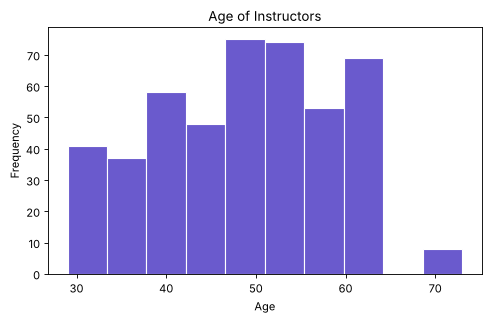

In [7]:
plt.figure(figsize=(7, 4))
plt.hist(ratings["age"], bins=10, color="slateblue", edgecolor="white")
plt.title("Age of Instructors")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Result:** Most instructors are between about 35 and 60 years old. Very few are above 65.

gender
male      268
female    195
Name: count, dtype: int64


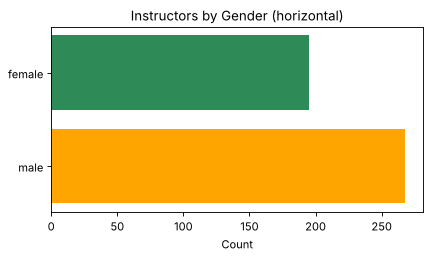

In [8]:
gender_counts = ratings["gender"].value_counts()
print(gender_counts)
plt.figure(figsize=(6, 3))
plt.barh(gender_counts.index, gender_counts.values, color=["orange", "seagreen"])
plt.title("Instructors by Gender (horizontal)")
plt.xlabel("Count")
plt.show()

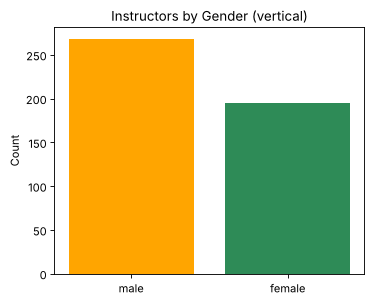

In [9]:
plt.figure(figsize=(5, 4))
plt.bar(gender_counts.index, gender_counts.values, color=["orange", "seagreen"])
plt.title("Instructors by Gender (vertical)")
plt.ylabel("Count")
plt.show()

**Result:** The data has 268 male and 195 female records. Both charts show the same counts, one with horizontal bars and one with vertical bars.

In [10]:
tenured_median = ratings.loc[ratings["tenure"] == "yes", "eval"].median()
print("Median evaluation score of tenured instructors:", tenured_median)

Median evaluation score of tenured instructors: 4.0


**Result:** The median evaluation score of tenured instructors is 4.0.